# 01 Data audit: what was pulled and what is wrong with it

Twelve NYC Open Data tables, Bronx and Brooklyn, 2018 onward, pulled with a resumable keyset-paged Socrata client into raw Parquet (gitignored). This notebook renders the
audit that `pipelines/audit.py` wrote to [`docs/data_audit.md`](../docs/data_audit.md); it does not touch the raw data.

**The two findings that shape everything after this:**
1. About one in six closed HPD complaint problems ends with *the inspector could not gain access*. That is a censoring mechanism: no inspection, no violation.
2. HPD violation text is mostly free-form (half of the texts are unique after normalising), so text is a hard signal to use (Phase 7 tests that).


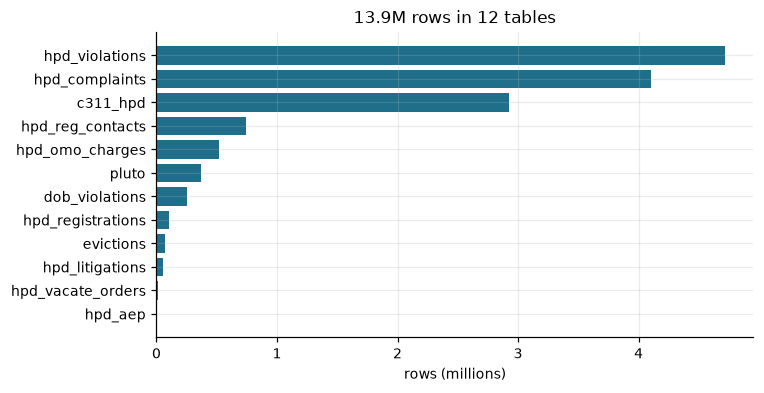

In [1]:
from nbutil import *
import re
audit = (DOCS / "data_audit.md").read_text()
section = lambda a, b: audit.split(a, 1)[1].split(b, 1)[0]

rows = re.findall(r"^- (\w+): ([\d,]+) rows, (\d+) columns", section("## Row counts and manifests", "## Key uniqueness"), flags=re.M)
counts = pd.DataFrame(rows, columns=["table", "rows", "ncols"]).assign(rows=lambda d: d.rows.map(num), ncols=lambda d: d.ncols.map(num))
fig, ax = plt.subplots(figsize=(7, 3.6))
d = counts.sort_values("rows")
ax.barh(d.table, d.rows / 1e6, color=BLUE)
ax.set_xlabel("rows (millions)")
ax.set_title(f"{counts.rows.sum() / 1e6:.1f}M rows in {len(counts)} tables")
plt.show()

## Keys and joins

Every table that has a natural key was tested for duplicates. The BBL (borough-block-lot, the building's tax lot id) is the join key across tables; the audit measures how many distinct BBLs in each table exist in PLUTO (the lot table).
The three tables that match only 60 to 78% are the ones pulled **citywide** (no borough filter in `pipelines/ingest/datasets.py`: OMO charges, vacate orders, AEP), so their misses are lots outside the Bronx and Brooklyn, not join failures.

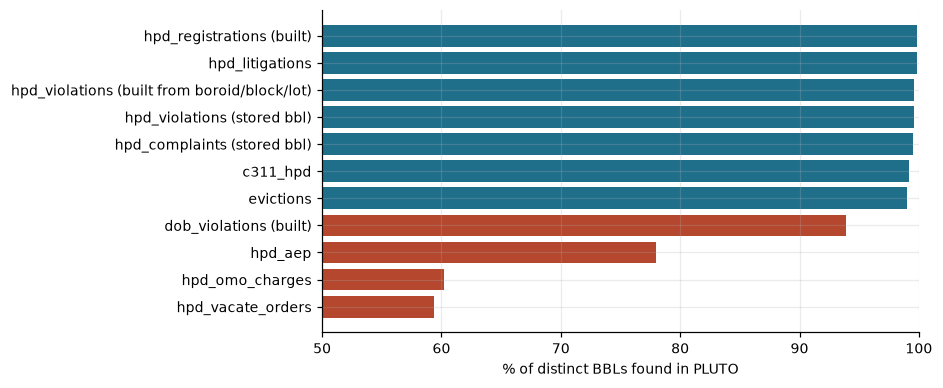

,table,distinct_bbl,in_pluto,pct_in_pluto
0,hpd_violations (stored bbl),109812.0,109359.0,99.6
1,hpd_violations (built from boroid/block/lot),109972.0,109529.0,99.6
2,hpd_complaints (stored bbl),85391.0,84995.0,99.5
3,c311_hpd,75555.0,74956.0,99.2
4,evictions,23252.0,23028.0,99.0
5,hpd_litigations,19917.0,19882.0,99.8
6,hpd_omo_charges,68821.0,41446.0,60.2
7,hpd_vacate_orders,8042.0,4773.0,59.4
8,hpd_aep,3628.0,2829.0,78.0
9,hpd_registrations (built),102068.0,101918.0,99.8


In [2]:
cov = []
for name, a, b, pct in re.findall(r"^- ([^:]+): .*?distinct bbl ([\d,]+), in PLUTO ([\d,]+) \(([\d.]+)%\)", section("## BBL quality", "## HPD complaints"), flags=re.M):
    cov.append((name, num(a), num(b), float(pct)))
cov = pd.DataFrame(cov, columns=["table", "distinct_bbl", "in_pluto", "pct_in_pluto"])
fig, ax = plt.subplots(figsize=(7, 3.8))
d = cov.sort_values("pct_in_pluto")
ax.barh(d.table, d.pct_in_pluto, color=[RED if p < 95 else BLUE for p in d.pct_in_pluto])
ax.set_xlim(50, 100); ax.set_xlabel("% of distinct BBLs found in PLUTO")
plt.show()
cov.round(1)

In [3]:
dups = re.findall(r"^- (\w+) key \(([^)]*)\): ([\d,]+) rows, ([\d,]+) distinct, duplicates ([\d,]+)", section("## Key uniqueness", "## Date sanity"), flags=re.M)
pd.DataFrame(dups, columns=["table", "key", "rows", "distinct", "duplicates"]).assign(duplicates=lambda d: d.duplicates.map(num)).query("duplicates > 0")

,table,key,rows,distinct,duplicates
6,hpd_registrations,registrationid,"106,661","106,656",5.0
7,hpd_reg_contacts,registrationcontactid,"744,753","743,302",1451.0
10,hpd_aep,"building_id, aep_start_date","4,387","4,386",1.0


Only registrations, registration contacts and AEP have duplicate keys; they are deduplicated in staging with documented rules (newest registration, most complete contact row, the AEP row that has a discharge date).

## Censoring: complaints closed because the inspector could not get in

HPD closes a complaint problem with a status text. One of those texts says HPD "was not able to gain access". The share is large and differs by borough and year.

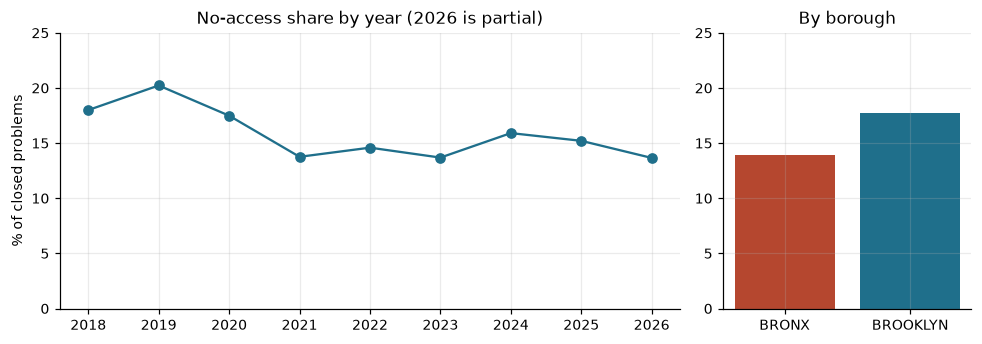

- strict 'not able to gain access' rows: 642,865 (15.68%); distinct complaints 401,107 (16.66%)


In [4]:
na = section("## HPD complaints: inspector no-access", "## Text diversity")
by_year = pd.DataFrame(re.findall(r"(\d{4}) ([\d.]+)%", re.search(r"strict rate by year: (.*)", na).group(1)), columns=["year", "pct"]).astype({"pct": float})
by_boro = pd.DataFrame(re.findall(r"([A-Z]+) ([\d.]+)%", re.search(r"strict rate by borough: (.*)", na).group(1)), columns=["borough", "pct"]).astype({"pct": float})
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [3, 1.2]})
a.plot(by_year.year, by_year.pct, "-o", color=BLUE); a.set_ylim(0, 25); a.set_ylabel("% of closed problems"); a.set_title("No-access share by year (2026 is partial)")
b.bar(by_boro.borough, by_boro.pct, color=[RED, BLUE]); b.set_ylim(0, 25); b.set_title("By borough")
plt.tight_layout(); plt.show()
print(re.search(r"- strict 'not able to gain access' rows: (.*)", na).group(0))

Reading: about 16% of closed problems (17% of distinct complaints) end with no access. Brooklyn is higher than the Bronx. Phase 4 asks whether buildings where this happens a lot are quietly worse off; the answer there is no (see notebook 04).

## How templated is the text?

In [5]:
td = section("## Text diversity", "\x00") if "\x00" in audit else audit.split("## Text diversity", 1)[1]
out = []
for col, a, b, c in re.findall(r"- (\S+): .*?top 10 / 100 / 1000 normalized texts cover ([\d.]+)% / ([\d.]+)% / ([\d.]+)% of rows", td):
    out.append((col, float(a), float(b), float(c)))
pd.DataFrame(out, columns=["column", "top 10 cover %", "top 100 cover %", "top 1000 cover %"])

,column,top 10 cover %,top 100 cover %,top 1000 cover %
0,hpd_violations.novdescription,16.54,19.77,25.30
1,dob_violations.description,80.90,88.82,90.58


HPD violation descriptions are mostly unique (top 1,000 texts cover about a quarter of rows), while DOB descriptions are heavily templated (top 100 cover 89%). That is why the Phase 7 text experiments were worth running and why they could have gone either way.

## Takeaways
- Pull is complete (every manifest says `complete=True`) and keys are clean; the only real join loss is the three citywide tables.
- The no-access mechanism is real and sizeable. It is a **property of the measurement**: the absence of a violation can mean nobody got in to look.
- Dates contain impossible values in a few columns (e.g. year 9202, 2040) that are filtered by the stated rule in Phase 2, not ignored.
